In [1]:
import sys


In [1]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

In [2]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml(
"mnist_784",
as_frame=False
)
X, y = mnist["data"], mnist["target"]

In [3]:
print(X.shape)
print(y.shape)

(70000, 784)
(70000,)


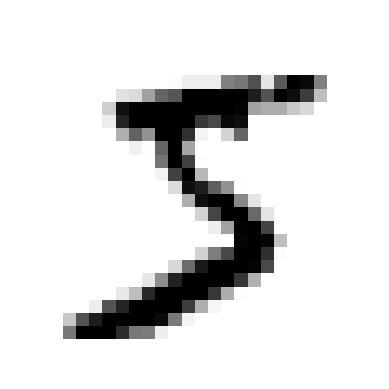

In [4]:
import matplotlib.pyplot as plt
some_digit = X[0]
some_digit_image = some_digit.reshape(
28, 28
)
plt.imshow(
some_digit_image,
cmap="binary"
)
plt.axis("off")
plt.show()

In [8]:
print(y[0])

5


In [9]:
import numpy as np


In [10]:
y = y.astype(np.uint8)


In [ ]:
X_train = X[:60000]
X_test = X[60000:]

y_train = y[:60000]
y_test = y[60000:]

In [12]:
y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)

In [ ]:
#Training a binary classifier
from sklearn.linear_model import SGDClassifier
sgd_clf = SGDClassifier(
random_state=42
)
sgd_clf.fit(
X_train,
y_train_5
)

,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only i

In [14]:
sgd_clf.predict(
[some_digit]
)

array([ True])

In [ ]:
#Evaluating the accuracy and cross validating
from sklearn.model_selection import cross_val_score
cross_val_score(
sgd_clf,
X_train,
y_train_5,
cv=3,
scoring="accuracy"
)

array([0.95035, 0.96035, 0.9604 ])

In [16]:
#Confusion matrix to give detailed information about classification performance
from sklearn.model_selection import cross_val_predict
y_train_pred = cross_val_predict(
    sgd_clf,
    X_train,
    y_train_5,
    cv=3
)

In [ ]:
#calculate confusion matrix
from sklearn.metrics import confusion_matrix
confusion_matrix(
    y_train_5,
    y_train_pred
)

In [ ]:
#calculating both metrics
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
precision = precision_score(
y_train_5,
y_train_pred
)
recall = recall_score(
y_train_5,
y_train_pred
)
print("Precision:", precision)
print("Recall:", recall)

Precision: 0.8370879772350012
Recall: 0.6511713705958311


In [18]:
from sklearn.metrics import f1_score
f1 = f1_score(
y_train_5,
y_train_pred
)
print("F1-score:", f1)

F1-score: 0.7325171197343847


In [ ]:
#precision and recall trade off
y_scores = cross_val_predict(
sgd_clf,
X_train,
y_train_5,
cv=3,
method="decision_function"
)

In [20]:
threshold = 0
y_some_digit_pred = (
y_scores >= threshold
)

In [ ]:
#precision recall curve
from sklearn.metrics import precision_recall_curve
precisions, recalls, thresholds = (
precision_recall_curve(
y_train_5,
y_scores
)
)

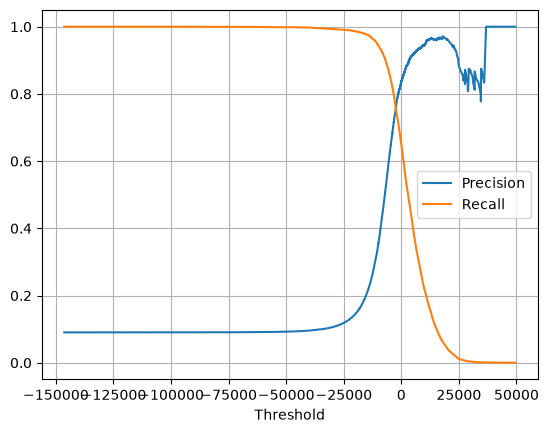

In [22]:
plt.plot(
thresholds,
precisions[:-1],
label="Precision"
)
plt.plot(
thresholds,
recalls[:-1],
label="Recall"
)
plt.xlabel("Threshold")
plt.grid()
plt.legend()
plt.show()

In [ ]:
#ROC_CURVE
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(
y_train_5,
y_scores
)

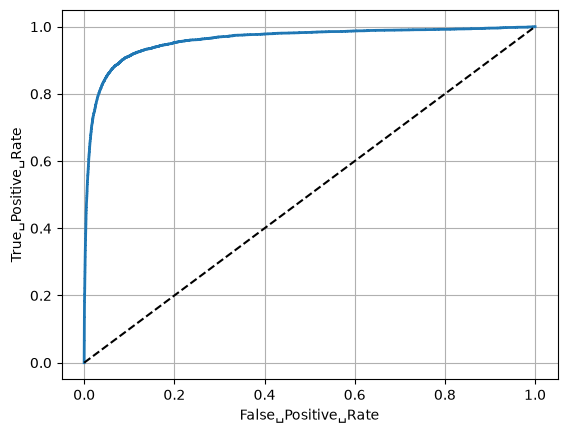

In [24]:
plt.plot(
fpr,
tpr,
linewidth=2
)
plt.plot(
[0, 1],
[0, 1],
"k--"
)
plt.xlabel("False␣Positive␣Rate")
plt.ylabel("True␣Positive␣Rate")
plt.grid()
plt.show()

In [25]:
from sklearn.metrics import roc_auc_score
roc_auc = roc_auc_score(
y_train_5,
y_scores
)
print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9604938554008616


In [ ]:
#MULTICLASS CLASSIFICATION
sgd_clf.fit(
X_train,
y_train
)

In [26]:
sgd_clf.predict(
[some_digit]
)

array([ True])

In [27]:
some_digit_scores = (
sgd_clf.decision_function(
[some_digit]
)
)
print(some_digit_scores)

[2164.22030239]


In [28]:
print(
sgd_clf.classes_
)

[False  True]


In [29]:
#evaluating the classifier using cross validation
y_train_pred = cross_val_predict(
sgd_clf,
X_train,
y_train,
cv=3
)

In [33]:
from sklearn.metrics import confusion_matrix


In [34]:
#calculating the confusion matrix
conf_mx = confusion_matrix(
    y_train,
    y_train_pred
)

print(conf_mx)

[[5565    0   69   16   21   73   50   13   83   33]
 [   3 6399   95   20   15   47   16   17  110   20]
 [  33   56 5202   93   69   42  158   74  213   18]
 [  12   32  218 4953   24  446   33   66  212  135]
 [  11   26   47    5 5285   25   70   36   83  254]
 [  40   23   58  149   85 4631  166   23  156   90]
 [  24   11   66    6   26  115 5627    4   37    2]
 [  22   24  103   33  124   41   10 5221   72  615]
 [  26  101  156  121   48  461   76   47 4647  168]
 [  23   14   55   72  503  125    5  447  123 4582]]


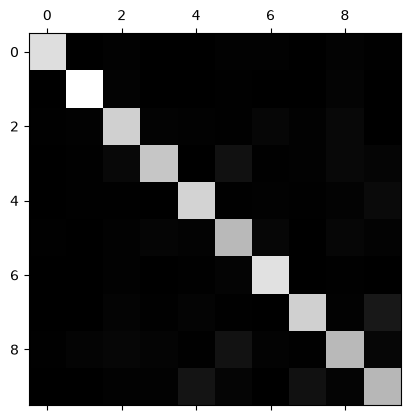

In [35]:
#visualizing the confusion matrix
plt.matshow(
    conf_mx,
    cmap=plt.cm.gray
)
plt.show()

In [36]:
#Multilabel classification
y_train_large = (
    y_train >= 7
)
y_train_odd = (
    y_train % 2 == 1
)
y_multilabel = np.c_[
    y_train_large,
    y_train_odd
]

In [37]:
#train a classifier
from sklearn.neighbors import KNeighborsClassifier
knn_clf = KNeighborsClassifier()
knn_clf.fit(
    X_train,
    y_multilabel
)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier",list,"[array([False, True]), array([False, True])]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [38]:
#Make a prediction
knn_clf.predict(
[some_digit]
)

array([[False,  True]])

In [39]:
y_train_knn_pred = cross_val_predict(
knn_clf,
X_train,
y_multilabel,
cv=3
)

In [40]:
f1_score(
y_multilabel,
y_train_knn_pred,
average="macro"
)

0.9764102655606048